# 03 — Pré-processamento, treinamento e avaliação dos modelos

1. Separação treino/teste · 2. Pipeline de pré-processamento · 3. Modelos + ajuste de hiperparâmetros
(GridSearchCV / RandomizedSearchCV com validação cruzada 5-fold) · 4. Avaliação no teste e benchmark ·
5. Diagnóstico do melhor modelo

In [1]:
from pathlib import Path
import sys, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import olist_features as of

TAB, FIG, MOD = ROOT / "resultados/tabelas", ROOT / "resultados/graficos", ROOT / "resultados/modelos"
for p in (TAB, FIG, MOD): p.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
SEED = 42

data = of.load_dataset()
X, y = data[of.FEATURES], data[of.TARGET]
print(X.shape)

(96164, 30)


## 1. Separação treino / teste (80% / 20%)

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)   # validação cruzada dentro do treino
print(f"Treino: {len(X_train):,} pedidos | Teste: {len(X_test):,} pedidos")
print(f"Média do alvo — treino {y_train.mean():.2f} | teste {y_test.mean():.2f} dias")

Treino: 76,931 pedidos | Teste: 19,233 pedidos
Média do alvo — treino 12.31 | teste 12.37 dias


## 2. Pipeline de pré-processamento

Tudo é ajustado **somente nos dados de treino** (dentro de cada fold), evitando vazamento:

| Grupo | Colunas | Etapas |
|---|---|---|
| Numéricas assimétricas | valores R$, peso, volume, distâncias | `SimpleImputer(median)` → `log1p` → `StandardScaler` |
| Demais numéricas | contagens, dimensões, frações, hora | `SimpleImputer(median)` → `StandardScaler` |
| Categóricas | UF, categoria, dia da semana, mês | `SimpleImputer("desconhecido")` → `OneHotEncoder` |

In [3]:
LOG_COLS = ["products_value_total", "freight_value_total", "order_value_total", "weight_g_total", "weight_g_mean",
            "volume_cm3_total", "distance_km_mean", "distance_km_min", "distance_km_max"]
OTHER_NUM = [c for c in of.NUMERIC if c not in LOG_COLS]

preprocess = ColumnTransformer([
    ("num_log", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                          ("scaler", StandardScaler())]), LOG_COLS),
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), OTHER_NUM),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="desconhecido")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), of.CATEGORICAL),
])
n_cols = preprocess.fit(X_train).transform(X_train.head()).shape[1]
print(f"{len(of.FEATURES)} features originais → {n_cols} colunas após o one-hot")
preprocess

30 features originais → 146 colunas após o one-hot


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_log', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featu

## 3. Modelos e ajuste de hiperparâmetros

Quatro modelos (lineares, árvore e dois ensembles) + um baseline que sempre prevê a mediana.
Critério de escolha: **menor MAE na validação cruzada 5-fold**.

In [4]:
MODELS = {
    "Ridge": (Ridge(), "Grid", {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]}),
    "Árvore de Decisão": (DecisionTreeRegressor(random_state=SEED), "Grid",
        {"model__max_depth": [8, 12, 16, None], "model__min_samples_leaf": [50, 100, 200, 400]}),
    "Random Forest": (RandomForestRegressor(random_state=SEED, n_jobs=1), "Randomized",
        {"model__n_estimators": [100, 200], "model__max_depth": [15, 25, None],
         "model__min_samples_leaf": [5, 10, 20], "model__max_features": [0.3, 0.5]}),
    "Gradient Boosting": (HistGradientBoostingRegressor(random_state=SEED), "Randomized",
        {"model__learning_rate": [0.03, 0.05, 0.1], "model__max_iter": [300, 600],
         "model__max_leaf_nodes": [31, 63, 127], "model__min_samples_leaf": [20, 50, 100],
         "model__l2_regularization": [0, 1]}),
}
SCORING = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

searches, cv_rows, best_rows = {}, [], []
for name, (model, kind, grid) in MODELS.items():
    pipe = Pipeline([("pre", preprocess), ("model", model)])
    jobs = 4 if name == "Gradient Boosting" else -1
    common = dict(cv=cv, scoring=SCORING, refit="MAE", n_jobs=jobs)
    search = (GridSearchCV(pipe, grid, **common) if kind == "Grid"
              else RandomizedSearchCV(pipe, grid, n_iter=10, random_state=SEED, **common))
    t0 = time.time(); search.fit(X_train, y_train); secs = time.time() - t0
    searches[name] = search
    res = pd.DataFrame(search.cv_results_)
    for _, r in res.iterrows():
        cv_rows.append({"modelo": name, "params": json.dumps({k.replace("model__", ""): v for k, v in r.params.items()}, default=str),
                        "MAE_cv": -r.mean_test_MAE, "RMSE_cv": -r.mean_test_RMSE, "R2_cv": r.mean_test_R2,
                        "rank": r.rank_test_MAE})
    best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    best_rows.append({"modelo": name, "busca": f"{kind}SearchCV", "combinações": len(res),
                      "melhores_parametros": json.dumps(best, ensure_ascii=False, default=str),
                      "MAE_cv": -search.best_score_, "tempo_s": round(secs)})
    print(f"{name:18s} {kind}SearchCV · {len(res)} combinações × 5 folds · {secs:5.0f}s · MAE_cv={-search.best_score_:.3f} · {best}")

pd.DataFrame(cv_rows).sort_values(["modelo", "rank"]).to_csv(TAB / "03_busca_hiperparametros.csv", index=False)
best_params = pd.DataFrame(best_rows)
best_params.to_csv(TAB / "03_melhores_parametros.csv", index=False)
best_params

Ridge              GridSearchCV · 6 combinações × 5 folds ·    14s · MAE_cv=4.734 · {'alpha': 1}


Árvore de Decisão  GridSearchCV · 16 combinações × 5 folds ·    29s · MAE_cv=4.718 · {'max_depth': 16, 'min_samples_leaf': 100}


Random Forest      RandomizedSearchCV · 10 combinações × 5 folds ·   682s · MAE_cv=4.536 · {'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 25}


Gradient Boosting  RandomizedSearchCV · 10 combinações × 5 folds ·   269s · MAE_cv=4.493 · {'min_samples_leaf': 100, 'max_leaf_nodes': 127, 'max_iter': 300, 'learning_rate': 0.03, 'l2_regularization': 1}


,modelo,busca,combinações,melhores_parametros,MAE_cv,tempo_s
0,Ridge,GridSearchCV,6,"{""alpha"": 1}",4.7341,14
1,Árvore de Decisão,GridSearchCV,16,"{""max_depth"": 16, ""min_samples_leaf"": 100}",4.7176,29
2,Random Forest,RandomizedSearchCV,10,"{""n_estimators"": 200, ""min_samples_leaf"": 5, ""...",4.5360,682
3,Gradient Boosting,RandomizedSearchCV,10,"{""min_samples_leaf"": 100, ""max_leaf_nodes"": 12...",4.4931,269


Exemplo do processo de otimização: MAE na validação cruzada para cada combinação testada da Árvore de Decisão.

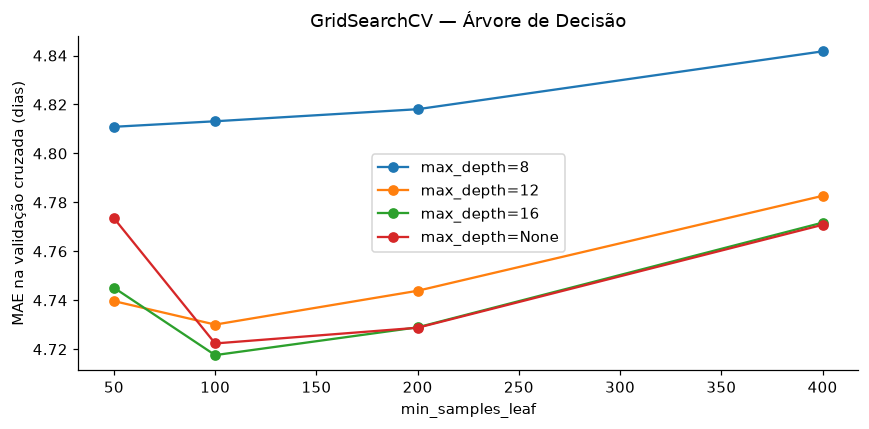

In [5]:
tree = pd.DataFrame(searches["Árvore de Decisão"].cv_results_)
depths = tree.param_model__max_depth.astype(object).where(tree.param_model__max_depth.notna(), "None").astype(str)
fig, ax = plt.subplots(figsize=(8, 4))
for depth in ["8", "12", "16", "None"]:
    g = tree[depths == depth].assign(leaf=lambda d: d.param_model__min_samples_leaf.astype(int)).sort_values("leaf")
    ax.plot(g["leaf"], -g.mean_test_MAE, marker="o", label=f"max_depth={depth}")
ax.set(xlabel="min_samples_leaf", ylabel="MAE na validação cruzada (dias)", title="GridSearchCV — Árvore de Decisão")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "07_gridsearch_arvore.png", dpi=150); plt.show()

## 4. Avaliação no conjunto de teste e benchmark dos modelos

In [6]:
def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": root_mean_squared_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}

baseline = DummyRegressor(strategy="median").fit(X_train, y_train)
preds = {"Baseline (mediana)": baseline.predict(X_test)}
preds.update({name: s.best_estimator_.predict(X_test) for name, s in searches.items()})
test = pd.DataFrame([{"modelo": n, **metrics(y_test, p)} for n, p in preds.items()])
test["MAE_cv"] = test.modelo.map(best_params.set_index("modelo").MAE_cv)
test = test.sort_values("MAE").reset_index(drop=True)
test.to_csv(TAB / "03_metricas_teste.csv", index=False)
test

,modelo,MAE,RMSE,R2,MAE_cv
0,Gradient Boosting,4.5353,6.6371,0.3896,4.4931
1,Random Forest,4.5835,6.6844,0.3809,4.5360
2,Árvore de Decisão,4.7904,6.9295,0.3347,4.7176
3,Ridge,4.8143,6.9382,0.3330,4.7341
4,Baseline (mediana),5.9696,8.7680,-0.0652,NaN


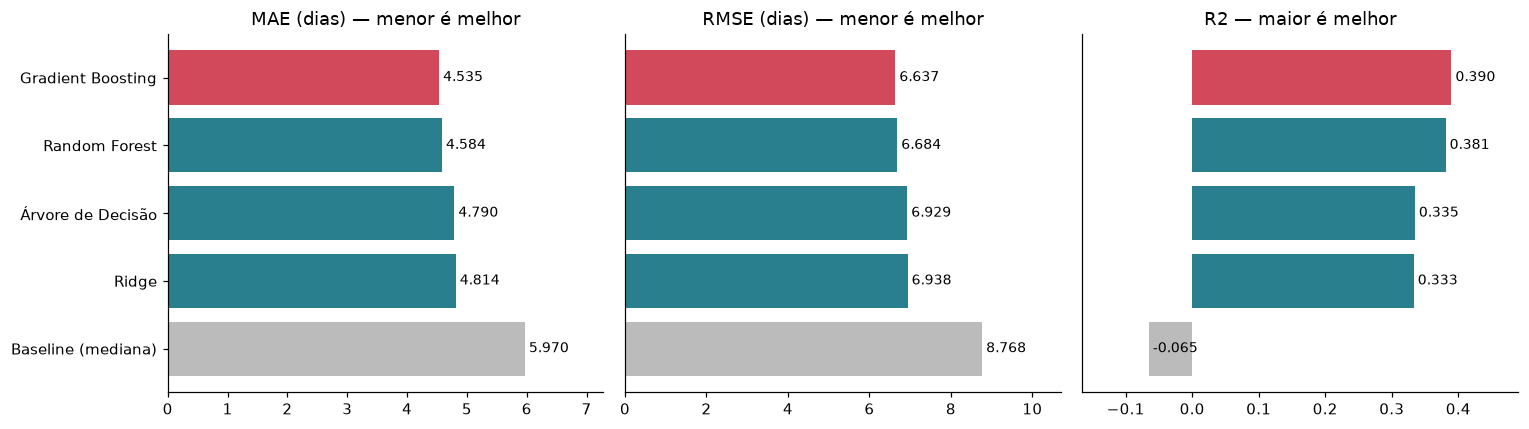

In [7]:
order = test.sort_values("MAE", ascending=False)
colors = ["#bbbbbb" if m.startswith("Baseline") else "#2a7f8f" for m in order.modelo]
colors[-1] = "#d1495b"
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, m in zip(axes, ["MAE", "RMSE", "R2"]):
    ax.barh(order.modelo, order[m], color=colors)
    for i, v in enumerate(order[m]): ax.text(v, i, f" {v:.3f}", va="center", fontsize=9)
    ax.margins(x=0.22)
    ax.set_title(m + (" (dias) — menor é melhor" if m != "R2" else " — maior é melhor"))
axes[1].set_yticks([]); axes[2].set_yticks([])
fig.tight_layout(); fig.savefig(FIG / "08_comparacao_modelos.png", dpi=150); plt.show()

In [8]:
best_name = test.loc[~test.modelo.str.startswith("Baseline"), "modelo"].iloc[0]
best_model = searches[best_name].best_estimator_
pred = preds[best_name]
base_mae = float(test.set_index("modelo").loc["Baseline (mediana)", "MAE"])
best_row = test.set_index("modelo").loc[best_name]
olist_est = data.loc[X_test.index, "olist_estimated_days"]
olist_mae = float(mean_absolute_error(y_test, olist_est))
resumo = {
    "n_total": int(len(data)), "n_treino": int(len(X_train)), "n_teste": int(len(X_test)),
    "n_colunas_pos_onehot": int(n_cols),
    "melhor_modelo": best_name,
    "mae_teste": float(best_row["MAE"]), "rmse_teste": float(best_row["RMSE"]), "r2_teste": float(best_row["R2"]),
    "baseline_mae": base_mae, "reducao_mae_pct": float((1 - best_row["MAE"] / base_mae) * 100),
    "olist_prazo_mae": olist_mae,
}
(TAB / "03_resumo_modelo.json").write_text(json.dumps(resumo, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Melhor modelo: {best_name}")
print(f"MAE {resumo['mae_teste']:.2f} dias vs baseline {base_mae:.2f} → redução de {resumo['reducao_mae_pct']:.1f}%")
print(f"Prazo informado pela Olist: MAE {olist_mae:.2f} dias (prazo conservador, não é estimativa pontual)")
joblib.dump(best_model, MOD / "melhor_modelo.joblib", compress=3)

Melhor modelo: Gradient Boosting
MAE 4.54 dias vs baseline 5.97 → redução de 24.0%
Prazo informado pela Olist: MAE 12.65 dias (prazo conservador, não é estimativa pontual)


['C:\\trabCDados\\projeto-olist\\resultados\\modelos\\melhor_modelo.joblib']

## 5. Diagnóstico do melhor modelo

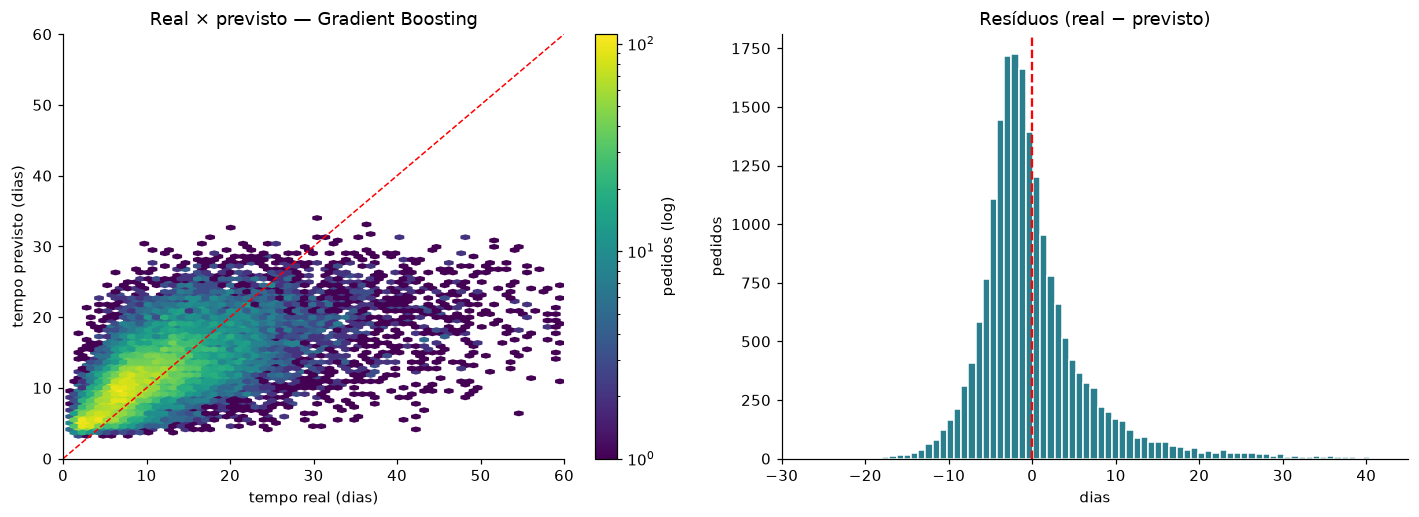

,pedidos,real_medio,previsto_medio,MAE
faixa,,,,
0–7,5238,4.6429,8.0117,3.4763
7–14,7954,10.0782,12.0365,3.2385
14–21,3553,16.8960,15.2735,4.0236
21–30,1614,24.4761,17.3908,7.4383
30–60,874,38.7423,19.3500,19.4021


In [9]:
res = y_test - pred
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
hb = axes[0].hexbin(y_test, pred, gridsize=60, bins="log", cmap="viridis", mincnt=1)
axes[0].plot([0, 60], [0, 60], "r--", lw=1); axes[0].set(xlim=(0, 60), ylim=(0, 60),
    xlabel="tempo real (dias)", ylabel="tempo previsto (dias)", title=f"Real × previsto — {best_name}")
fig.colorbar(hb, ax=axes[0], label="pedidos (log)")
axes[1].hist(res, bins=80, color="#2a7f8f", edgecolor="white"); axes[1].axvline(0, color="r", ls="--")
axes[1].set(title="Resíduos (real − previsto)", xlabel="dias", ylabel="pedidos", xlim=(-30, 45))
fig.tight_layout(); fig.savefig(FIG / "09_real_vs_previsto.png", dpi=150); plt.show()

faixas = pd.cut(y_test, [0, 7, 14, 21, 30, 60], labels=["0–7", "7–14", "14–21", "21–30", "30–60"])
por_faixa = pd.DataFrame({"faixa": faixas, "real": y_test, "prev": pred, "erro": res.abs()}).groupby("faixa", observed=True).agg(
    pedidos=("real", "size"), real_medio=("real", "mean"), previsto_medio=("prev", "mean"), MAE=("erro", "mean"))
por_faixa.to_csv(TAB / "03_erro_por_faixa.csv")
por_faixa

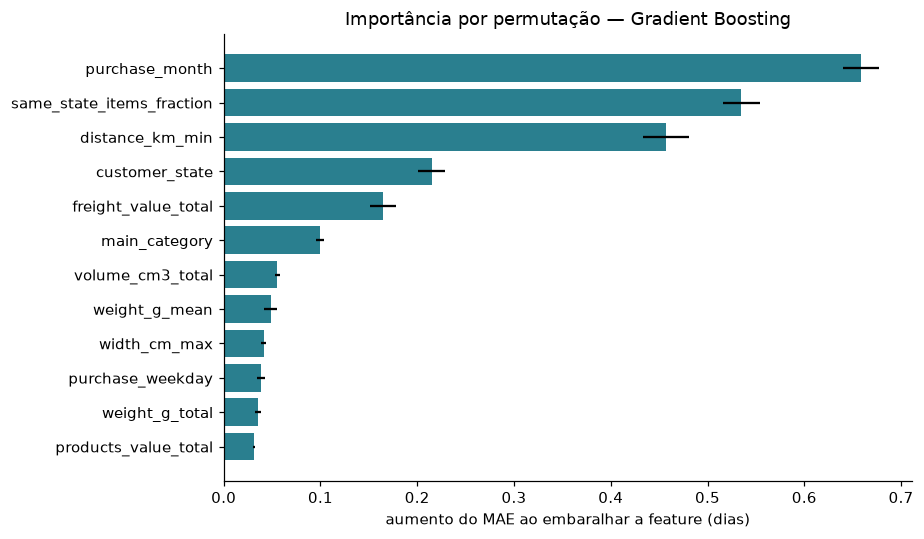

In [10]:
sample = X_test.sample(8000, random_state=SEED)
imp = permutation_importance(best_model, sample, y_test.loc[sample.index], scoring="neg_mean_absolute_error",
                             n_repeats=5, random_state=SEED, n_jobs=4)
importance = pd.DataFrame({"feature": of.FEATURES, "aumento_MAE": imp.importances_mean, "std": imp.importances_std})
importance = importance.sort_values("aumento_MAE", ascending=False)
importance.to_csv(TAB / "03_importancia_features.csv", index=False)
top = importance.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(top.feature, top.aumento_MAE, xerr=top["std"], color="#2a7f8f")
ax.set(title=f"Importância por permutação — {best_name}", xlabel="aumento do MAE ao embaralhar a feature (dias)")
fig.tight_layout(); fig.savefig(FIG / "10_importancia_features.png", dpi=150); plt.show()

## 6. Conclusão

- Todos os modelos superam com folga o baseline; os ensembles (Gradient Boosting / Random Forest) foram os melhores.
- O modelo escolhido erra em média ~4–5 dias (MAE), contra ~6 do baseline e ~12 do prazo informado pela Olist.
- R² ≈ 0,3–0,4: parte relevante da variação do prazo depende de fatores ausentes no dataset (transportadora,
  greves, estoque do vendedor, clima), por isso entregas muito longas continuam subestimadas.
- **Melhorias futuras:** features de histórico do vendedor (tempo médio de postagem), transportadora/rota,
  feriados e sazonalidade (Black Friday), prever com a data de postagem, modelos de quantis para dar um intervalo de prazo.